# Personalized Assortments with Scarce Inventory: a Data-to-Decision Model for the 30-Customer Simulation

**Question.** Thirty customers arrive one at a time. Each is of type A, B or C (revealed on arrival). We hold
6 units each of products 1, 2, 3, priced \$10, \$15, \$20. For every customer we choose which in-stock products to
show; the customer buys at most one. **Which assortment should we show each customer to maximize expected total
revenue?**

Pipeline (Lecture 14A *data → choice model → optimize*, extended to sequential demand as in Lecture 14B):
1. **Learn** each type's choice behaviour from `large_choice_training_data.csv` (per-type MNL by maximum likelihood, checked against a model-free estimate).
2. **Optimize** over the whole selling horizon with an exact dynamic program (DP), and compare against the class baselines (show-all, myopic greedy, inventory balancing, LP bid prices).
3. **Stress-test** the recommendation against the things we do not know: the arrival process of types and estimation error.

Supporting code: `rm_model.py` (all models and algorithms), `play.py` (live helper for the simulation).

## Summary of findings

* **The data support a per-type MNL.** Every type saw every assortment, so choice probabilities are measured directly.
  A separate MNL for each type reproduces all observed frequencies within 0.021, and it predicts held-out assortments
  within 0.030. The likelihood-ratio test does not reject MNL for types A and C (p = 0.47, 0.66). For type B, p = 0.034,
  which is not significant after a Bonferroni correction for three tests. One pooled MNL for all types is decisively
  rejected. The types differ sharply: A buys almost only product 3, B mostly product 2, and C has no favourite and a high purchase rate.
* **The problem is about selling out.** There are 18 units for 30 customers, so the \$270 maximum requires selling every unit.
  The main risk is leftover units of the \$10 product 1, which type A rarely buys.
* **Optimal policy (exact DP): \$268.6 expected revenue, 99.5% of the maximum, selling out in 91.5% of runs.**
  Opportunity costs reverse the price ranking: at the start, the adjusted prices are $\rho = (1.20, 0.84, 0.71)$ for products 1, 2, 3.
  The DP therefore opens with **A → {1,2,3}, B → {1,2}, C → {1,2}**. It pushes product 1 to the types willing to buy it and keeps product 3 for type A.
  We prove that each DP step is the class MNL assortment problem with these adjusted prices (Proposition 2) and verify this at all 30,780 (state, type) pairs.
* **Class baselines fall short in specific ways.** Myopic greedy (Lecture 14B) shows {2,3} to everyone at the start and strands
  product 1. It earns \$261.0 and sells out in only 56% of runs, which is worse than simply showing everything in stock (\$267.7).
  Inventory balancing earns \$265.8. LP bid prices are provably uninformative here (Proposition 4): perturbing them by $10^{-9}$ moves
  expected revenue anywhere between \$0 and \$267.7.
* **Robust to the unknown arrival process.** The DP is planned with the data's type mix. Across 7 different i.i.d. type mixes, it stays
  within \$0.29 of an oracle that knows the true mix. Across 6 adversarial block orders, its worst loss is \$2.79; for comparison, show-all loses up to \$3.14,
  inventory balancing \$12.17 and greedy \$23.85. Learning the mix online (adaptive DP) gains at most \$0.15 and loses up to \$14 under block orders, so we do not use it.
* **Robust to estimation error.** In 200 bootstrap re-estimations, the DP's opening decisions never change, and the mean revenue loss is below \$0.02.
* **Recommendation.** Use the DP built on the per-type MNL. `play.py` gives the move for each customer live, and `policy_table.csv` is the full lookup table.
  Even with the best policy, a single 30-customer run has a standard deviation of about \$5.5 (5th percentile \$260).

## 1. Model

**Notation.** Products $i \in \{1,2,3\}$ with prices $r = (10, 15, 20)$ and starting inventory $c = (6,6,6)$.
Customers $t = 1,\dots,T$ with $T = 30$. Customer $t$ has type $k_t \in \{A,B,C\}$, observed before we act.
Remaining inventory is $x \in \{0,\dots,6\}^3$, and $\mathcal A(x) = \{i : x_i \ge 1\}$ is the set of products in stock.
We choose an assortment $S_t \subseteq \mathcal A(x)$; a type-$k$ customer shown $S$ buys $i \in S$ with probability
$\phi_k(i,S)$ and buys nothing with probability $\phi_k(0,S)$.

**Choice model.** Per-type multinomial logit (MNL), as in class, with the no-purchase weight normalised to 1:
$$\phi_k(i,S) = \frac{v_{k,i}}{1+\sum_{j\in S} v_{k,j}}, \qquad \phi_k(0,S) = \frac{1}{1+\sum_{j\in S} v_{k,j}}.$$
Because the data contain every one of the 7 non-empty assortments for every type, we can also use the
**model-free** estimate $\hat\phi_k(j,S)$ = observed frequency. Every algorithm below accepts either.

**Arrivals (base assumption).** Types are i.i.d. with probabilities $p = (p_A, p_B, p_C)$, estimated by their shares in the data.
The arrival process is not given, so Section 6 relaxes this (shifted mixes, fixed compositions, adversarial orders).

**Dynamic program.** Let $V_t(x)$ be the optimal expected revenue from customers $t,\dots,T$ when inventory is $x$
(code: `V[t-1]`), with $V_{T+1} \equiv 0$:
$$V_t(x) = \sum_{k} p_k \max_{S \subseteq \mathcal A(x)} \Big\{ \sum_{i\in S} \phi_k(i,S)\,\big[r_i + V_{t+1}(x-e_i)\big] + \phi_k(0,S)\,V_{t+1}(x) \Big\}.$$
The state space has $30 \times 7^3 = 10{,}290$ states and only $2^3 = 8$ assortments, so it is solved exactly by enumeration in milliseconds.

Writing $\Delta_i(t,x) = V_t(x) - V_t(x-e_i)$ (the opportunity cost of selling one unit of $i$) and using
$\sum_{j \in S\cup\{0\}}\phi_k(j,S) = 1$, the term inside the max equals
$$V_{t+1}(x) + \sum_{i\in S}\phi_k(i,S)\,\big(r_i - \Delta_i(t+1,x)\big).$$
So **each decision is a single-customer assortment problem with "adjusted prices" $\rho_i = r_i - \Delta_i(t+1,x)$.**

**Modeling choices and why.**
* *Exact DP rather than an approximation:* the instance is small enough that the optimal policy (under the model) is computable, which gives a clean benchmark for every heuristic.
* *Type-specific models:* types are revealed, and Section 3 shows that one pooled model is decisively rejected.
* *What the model ignores:* customers are assumed not to learn or behave strategically, and their choice behaviour in the simulation is assumed to match the training data.

In [1]:
import itertools
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rm_model as rm
from rm_model import CAPACITY, HORIZON, K, LABELS, PRICES, SUBSETS, TYPES

pd.set_option("display.precision", 3)
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
SEED = 145

# Chart style: fixed categorical slot order (validated for colour-vision deficiency),
# hairline grid, muted axes, thin 2px lines.
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})
POLICY_STYLE = {  # name -> (colour, marker); colour follows the policy in every chart
    "DP (optimal)": (SLOT[0], "o"),
    "Show all in stock": (SLOT[1], "s"),
    "Inventory balancing": (SLOT[2], "^"),
    "Myopic greedy": (SLOT[3], "D"),
}

df, counts = rm.load_counts("large_choice_training_data.csv")
print(f"{len(df):,} observations; columns: {list(df.columns)}")

63,000 observations; columns: ['customer_type', 'assortment', 'result']


## 2. Data

Each row is one past customer: their type, the assortment they were shown, and the outcome (0 = no purchase).

In [2]:
design = pd.crosstab(df.assortment, df.customer_type).reindex(LABELS[1:])
design["total"] = design.sum(axis=1)
print("Number of observations per (assortment, type):")
display(design)

p_hat = counts.sum((1, 2)) / counts.sum()
print("Type shares in the data:", dict(zip(TYPES, p_hat.round(4))),
      "-> per 30 customers:", dict(zip(TYPES, (30 * p_hat).round(2))))

P_emp = rm.empirical_model(counts)
freq = pd.DataFrame(
    [{"type": TYPES[k], "assortment": LABELS[s], "N": counts[k, s].sum(),
      "P(no buy)": P_emp[k, s, 0], "P(buy 1)": P_emp[k, s, 1], "P(buy 2)": P_emp[k, s, 2],
      "P(buy 3)": P_emp[k, s, 3], "E[revenue] $": P_emp[k, s, 1:] @ PRICES}
     for k in range(K) for s in range(1, rm.N_SUB)]).set_index(["type", "assortment"])
print("Observed choice frequencies (model-free estimate) and single-customer expected revenue:")
display(freq)

Number of observations per (assortment, type):


customer_type,A,B,C,total
assortment,,,,
{1},3300,2100,3600,9000
{2},3300,2100,3600,9000
{3},3300,2100,3600,9000
"{1,2}",3300,2100,3600,9000
"{1,3}",3300,2100,3600,9000
"{2,3}",3300,2100,3600,9000
"{1,2,3}",3300,2100,3600,9000


Type shares in the data: {'A': np.float64(0.3667), 'B': np.float64(0.2333), 'C': np.float64(0.4)} -> per 30 customers: {'A': np.float64(11.0), 'B': np.float64(7.0), 'C': np.float64(12.0)}
Observed choice frequencies (model-free estimate) and single-customer expected revenue:


N  P(no buy)  P(buy 1)  P(buy 2)  P(buy 3)  E[revenue] $
type assortment                                                             
A    {1}         3300      0.825     0.175     0.000     0.000         1.755
     {2}         3300      0.842     0.000     0.158     0.000         2.368
     {3}         3300      0.381     0.000     0.000     0.619        12.376
     {1,2}       3300      0.722     0.141     0.138     0.000         3.470
     {1,3}       3300      0.352     0.074     0.000     0.574        12.221
     {2,3}       3300      0.371     0.000     0.070     0.559        12.233
     {1,2,3}     3300      0.342     0.060     0.060     0.538        12.259
B    {1}         2100      0.513     0.487     0.000     0.000         4.871
     {2}         2100      0.128     0.000     0.872     0.000        13.086
     {3}         2100      0.494     0.000     0.000     0.506        10.124
     {1,2}       2100      0.124     0.122     0.754     0.000        12.533
     {1,3}       2100      0.314     0.342     0.000     0.344        10.305
     {2,3}       2100      0.100     0.000     0.791     0.109        14.052
     {1,2,3}     2100      0.105     0.102     0.704     0.089        13.364
C    {1}         3600      0.339     0.661     0.000     0.000         6.608
     {2}         3600      0.331     0.000     0.669     0.000        10.037
     {3}         3600      0.317     0.000     0.000     0.683        13.661
     {1,2}       3600      0.191     0.396     0.412     0.000        10.147
     {1,3}       3600      0.198     0.402     0.000     0.400        12.028
     {2,3}       3600      0.194     0.000     0.412     0.395        14.069
     {1,2,3}     3600      0.147     0.284     0.286     0.283        12.794

**What the data look like.** The data are a *designed experiment*: every type saw every non-empty assortment,
with exactly the same counts per assortment (3,300 for A, 2,100 for B, 3,600 for C). Two consequences:
* The choice probability of **every** (type, assortment) pair is estimated directly, with standard error at most
  $\sqrt{0.25/2100} \approx 0.011$. We do not need a model to extrapolate to unseen assortments, but a model is still useful
  to smooth noise and to test whether the behaviour has MNL structure.
* The type shares (11/30, 7/30, 12/30) may reflect how the experiment was designed rather than how customers arrive
  in the simulation. We use them as the base estimate of $p$ but treat them as uncertain (Section 6).

## 3. Estimating the choice model

We fit one MNL per type by maximum likelihood (same likelihood as `MNL_main.ipynb`: $+\log v_{i_t}$ for each purchase,
$-\log(1+\sum_{i\in S_t} v_i)$ for each observation). The log-likelihood is concave, so Newton's method converges to the
global optimum. Standard errors come from the inverse Fisher information.

**Goodness of fit.** For each type, the *saturated* model (a free choice distribution for each of the 7 assortments,
$\sum_S |S| = 12$ parameters) nests the MNL (3 parameters). The likelihood-ratio statistic $2(\ell_{sat}-\ell_{MNL})$ is
approximately $\chi^2_9$ under the null hypothesis that the MNL is correct.

In [3]:
fits = [rm.fit_mnl(counts[k]) for k in range(K)]
V_hat = np.array([f["v"] for f in fits])
P_mnl = rm.mnl_model(V_hat)

rows = []
for k, f in enumerate(fits):
    dof = rm.n_free_params_saturated(counts[k]) - rm.N_PROD
    lr = rm.lr_test(f["loglik"], rm.saturated_loglik(counts[k]), dof)
    rows.append({"type": TYPES[k], "v1": f["v"][0], "v2": f["v"][1], "v3": f["v"][2],
                 "se(log v1)": f["se_beta"][0], "se(log v2)": f["se_beta"][1], "se(log v3)": f["se_beta"][2],
                 "converged": f["converged"], "LR stat": lr["LR"], "df": lr["df"], "p-value": lr["p_value"]})
fit_table = pd.DataFrame(rows).set_index("type")
display(fit_table)

pooled = rm.fit_mnl(counts.sum(0))
lr_pool = rm.lr_test(pooled["loglik"], sum(f["loglik"] for f in fits), 2 * rm.N_PROD)
print("Pooled MNL (ignores type) weights:", pooled["v"].round(3))
print(f"LR test pooled vs per-type MNL: stat = {lr_pool['LR']:.1f}, df = {lr_pool['df']}, p = {lr_pool['p_value']:.3g}")
print(f"Max |MNL - observed| over all (type, assortment, outcome): {np.abs(P_mnl - P_emp).max():.4f}")

,v1,v2,v3,se(log v1),se(log v2),se(log v3),converged,LR stat,df,p-value
type,,,,,,,,,,
A,0.200,0.189,1.590,0.028,0.029,0.018,True,8.699,9,0.466
B,1.012,6.945,1.007,0.029,0.029,0.029,True,18.098,9,0.034
C,2.012,2.074,2.043,0.020,0.020,0.020,True,6.738,9,0.664


Pooled MNL (ignores type) weights: [0.788 1.28  1.512]
LR test pooled vs per-type MNL: stat = 17398.4, df = 6, p = 0
Max |MNL - observed| over all (type, assortment, outcome): 0.0211


**Out-of-sample check (leave one assortment out).** A model is only useful if it predicts choices on assortments it has not
seen. For each type and each assortment $S$, we refit the MNL without the $S$ data and predict the choice
distribution on $S$.

In [4]:
rows = []
for k in range(K):
    for s in range(1, rm.N_SUB):
        c = counts[k].copy()
        c[s] = 0
        pred = rm.mnl_probs(rm.fit_mnl(c)["v"])[s]
        obs = P_emp[k, s]
        se = np.sqrt(obs * (1 - obs) / counts[k, s].sum())
        ok = rm.OUT_OK[s]
        rows.append({"type": TYPES[k], "held-out assortment": LABELS[s],
                     "max |pred - obs|": np.abs(pred - obs)[ok].max(),
                     "max |pred - obs| / SE": (np.abs(pred - obs)[ok] / se[ok]).max()})
loo = pd.DataFrame(rows)
display(loo.pivot(index="held-out assortment", columns="type", values="max |pred - obs|").reindex(LABELS[1:]))
print("Largest held-out error:", loo["max |pred - obs|"].max().round(4),
      "| largest in standard errors:", loo["max |pred - obs| / SE"].max().round(2))

type,A,B,C
held-out assortment,,,
{1},0.014,0.028,0.010
{2},0.001,0.002,0.008
{3},0.006,0.008,0.017
"{1,2}",0.005,0.029,0.006
"{1,3}",0.008,0.023,0.006
"{2,3}",0.017,0.022,0.009
"{1,2,3}",0.008,0.015,0.007


Largest held-out error: 0.0295 | largest in standard errors: 3.14


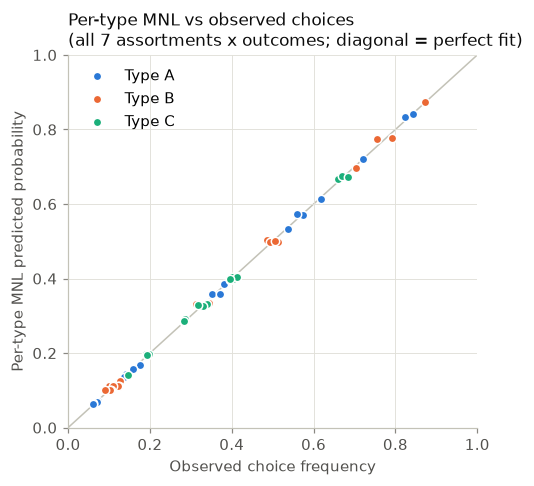

In [5]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for k in range(K):
    ok = rm.OUT_OK[1:]
    ax.scatter(P_emp[k, 1:][ok], P_mnl[k, 1:][ok], s=30, color=SLOT[k], edgecolor="white",
               linewidth=1, label=f"Type {TYPES[k]}", zorder=3)
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, zorder=1)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Observed choice frequency")
ax.set_ylabel("Per-type MNL predicted probability")
ax.set_title("Per-type MNL vs observed choices\n(all 7 assortments x outcomes; diagonal = perfect fit)", loc="left")
ax.legend(loc="upper left")
fig.savefig(FIG / "fig1_mnl_fit.png")
plt.show()

**Reading the fit.**
* *Preferences.* Type A has $v_3 = 1.59$ but $v_1 \approx v_2 \approx 0.2$, so it buys almost nothing except product 3. Type B strongly prefers
  product 2 ($v_2 = 6.9$). Type C has nearly equal weights (about 2.0 to 2.1): it buys whichever product is shown, about 67% of the time when shown one product.
* *Goodness of fit.* The MNL is not rejected for A or C. For B, $p = 0.034$; with three tests, the Bonferroni threshold is $0.05/3 \approx 0.017$, so this
  is not significant after correction. The largest held-out prediction error, 0.030 (type B, assortment {1,2} held out), is 3.1 standard errors, so B shows mild departures from MNL.
  Section 9 checks whether this matters for decisions by planning with the raw frequencies instead.
* *Personalization.* A single pooled MNL is rejected with LR = 17,398 on 6 degrees of freedom. The types genuinely behave differently.

## 4. Solution approaches and theory

We start from the class methods and identify where each falls short.

| Approach | Decision for customer $t$ of type $k$ | Uses arrival forecast? | Source |
|---|---|---|---|
| Show all in stock | $S = \mathcal A(x)$ | no | naive baseline |
| Myopic greedy | $\arg\max_{S\subseteq\mathcal A(x)} \sum_{i\in S} r_i\,\phi_k(i,S)$ | no | Lecture 14B (0.5-competitive) |
| Inventory balancing | prices discounted to $r_i\,\Psi(x_i/c_i)$, $\Psi(u)=\frac{e}{e-1}(1-e^{-u})$ | no | Golrezaei et al. (2014), cited in Lecture 14B |
| LP bid prices | prices discounted to $r_i - \pi_i$, $\pi$ = duals of the fluid LP | expected counts only | fluid relaxation (below) |
| **DP** | prices discounted to $r_i - \Delta_i(t+1,x)$ | full distribution | Section 1 |
| Adaptive DP | DP with $p$ re-estimated online (Dirichlet prior) | learns it | Section 6 |

**Fluid LP.** With $n_k$ = expected number of type-$k$ arrivals and $h_{k,S}$ = fraction of type-$k$ customers shown $S$:
$$\mathrm{LP}(n) = \max_{h\ge 0} \sum_k n_k \sum_S h_{k,S} R_k(S) \quad\text{s.t.}\quad \sum_k n_k \sum_S h_{k,S}\,\phi_k(i,S) \le c_i \ \ \forall i,\qquad \sum_S h_{k,S} = 1 \ \ \forall k,$$
where $R_k(S) = \sum_{i\in S} r_i\phi_k(i,S)$.

---
**Proposition 1 (monotonicity).** (a) If $x \ge x'$ componentwise then $V_t(x) \ge V_t(x')$; hence $\Delta_i(t,x) \ge 0$.
(b) $V_t(x) \ge V_{t+1}(x)$.

*Proof.* (a) Any policy that is feasible from $x'$ is also feasible from $x$: it only offers products that are in
stock in the $x'$ system, so they are in stock in the $x$ system too. The choice distribution depends only on the
assortment, so this policy earns the same expected revenue starting from $x$. (b) From state $(t,x)$, offer $\emptyset$ to
customer $t$ and then follow the optimal policy for customers $t+1,\dots,T$. Arrivals are i.i.d., so this earns $V_{t+1}(x)$. $\square$

**Proposition 2 (optimal decisions are revenue-ordered in adjusted prices).** Fix $t$, $x$ and type $k$ with an MNL
choice model. Let $\rho_i = r_i - \Delta_i(t+1,x)$ and $R^* = \max_{S\subseteq\mathcal A(x)} \sum_{i\in S}\phi_k(i,S)\rho_i$
(note that $R^*\ge 0$ because $S=\emptyset$ is allowed). Then $S^* = \{i\in\mathcal A(x) : \rho_i > R^*\}$ is an optimal decision.
Consequently, the optimal assortment always consists of the in-stock products with the highest adjusted prices,
and a product with $\rho_i \le 0$ never needs to be offered.

*Proof.* By the rewriting in Section 1, the DP decision maximizes $g(S)=\sum_{i\in S}\phi_k(i,S)\rho_i = \frac{\sum_{i\in S}v_i\rho_i}{1+\sum_{i\in S}v_i}$.
Multiplying out the denominator, for any $S$:
$$g(S)\ge R^* \iff \textstyle\sum_{i\in S} v_i(\rho_i - R^*) \ge R^*.$$
The left-hand sum is maximized over $S\subseteq\mathcal A(x)$ by including exactly the products with $\rho_i > R^*$, i.e., by $S^*$.
If $S^\circ$ is optimal, then $g(S^\circ) = R^*$, so its sum satisfies $\sum_{S^\circ} v_i(\rho_i-R^*) \ge R^*$.
Therefore the sum for $S^*$ is at least $R^*$ as well, which gives $g(S^*) \ge R^*$. $\square$

So every DP step is exactly the Lecture 13 MNL assortment problem with $r_i$ replaced by $\rho_i$, which the class
LP solves. **Interpretation:** when stock is scarce relative to the remaining customers, $\Delta_i \approx r_i$, and the
ranking of the $\rho_i$ can be the *reverse* of the price ranking.

**Proposition 3 (fluid upper bound).** For any arrival process with expected type counts $n_k$ and any non-anticipating
policy, expected revenue $\le \mathrm{LP}(n)$.

*Proof.* Let $y_{k,S} = \sum_t \Pr(k_t = k, S_t = S)$. Given the history and $(k_t,S_t)$, the purchase at $t$ is distributed
as $\phi_{k_t}(\cdot,S_t)$. Therefore expected revenue $=\sum_{k,S} y_{k,S}R_k(S)$ and expected sales of $i$ $=\sum_{k,S}y_{k,S}\phi_k(i,S)$.
Sales of $i$ can never exceed $c_i$, so the expected sales cannot either. Since $\sum_S y_{k,S} = n_k$, the vector $h_{k,S} = y_{k,S}/n_k$
is feasible for the LP with this objective value. $\square$

**Proposition 4 (bid prices are uninformative when demand exceeds supply).** If $\mathrm{LP}(n) = \sum_i r_i c_i$
(the fluid solution sells every unit), then $\pi = r$ is an optimal dual solution. With $\pi = r$, the bid-price rule
gives every assortment adjusted revenue 0, so its decisions are determined by tie-breaking and rounding.

*Proof.* The dual is $\min \sum_i c_i\pi_i + \sum_k \mu_k$ s.t. $\mu_k \ge n_k\sum_{i\in S}\phi_k(i,S)(r_i-\pi_i)$ for all $k,S$, and $\pi\ge 0$.
The point $\pi = r,\ \mu = 0$ is feasible with value $\sum_i r_ic_i = \mathrm{LP}(n)$, so it is optimal by weak duality. $\square$

The cells below verify Propositions 1, 2 and 4 numerically on this instance, and check that the class LP reproduces every DP step.

In [6]:
V_dp, pol_dp = rm.solve_dp(P_mnl, p_hat)
print(f"DP optimal expected revenue (MNL model, base arrivals): {V_dp[0][CAPACITY]:.3f}   (max possible = {PRICES @ CAPACITY:.0f})")

# Proposition 1
print("Prop 1(a) V nondecreasing in inventory:", all((np.diff(V_dp, axis=a) >= -1e-9).all() for a in (1, 2, 3)))
print("Prop 1(b) V_t >= V_{t+1}:", bool((V_dp[:-1] >= V_dp[1:] - 1e-9).all()))

# Proposition 2: structure + class LP (Lecture 13) on every state and type
t0, n_checked, struct_bad, lp_bad, empty_with_stock = time.time(), 0, 0, 0, 0
for t in range(HORIZON):
    D = rm.opportunity_costs(V_dp[t + 1])
    for x in itertools.product(*[range(c + 1) for c in CAPACITY]):
        avail = np.array(x) >= 1
        if not avail.any():
            continue
        rho = PRICES - D[(slice(None),) + x]
        feas = rm.feasible_subsets(x)
        for k in range(K):
            g = P_mnl[k, :, 1:] @ rho
            g[~feas] = -np.inf
            R_star = g.max()
            S_star = tuple(i for i in range(rm.N_PROD) if avail[i] and rho[i] > R_star + 1e-12)
            struct_bad += g[SUBSETS.index(S_star)] < R_star - 1e-9
            struct_bad += abs(g[pol_dp[t][x + (k,)]] - R_star) > 1e-9
            empty_with_stock += pol_dp[t][x + (k,)] == 0
            ai = np.flatnonzero(avail)
            _, lp_val = rm.mnl_opt_assortment_lp(V_hat[k][ai], rho[ai])
            lp_bad += abs(lp_val - R_star) > 1e-6
            n_checked += 1
print(f"Prop 2 checked at {n_checked:,} (state, type) pairs: structure violations = {struct_bad}, "
      f"class-LP mismatches = {lp_bad}, empty assortment offered while in stock = {empty_with_stock} "
      f"({time.time() - t0:.0f}s)")

# Proposition 4
lp_val, h_lp, bid = rm.fluid_lp(P_mnl, HORIZON * p_hat)
print(f"Fluid LP upper bound = {lp_val:.2f}; sum r_i c_i = {PRICES @ CAPACITY:.0f}; LP bid prices = {bid.round(4)}")

DP optimal expected revenue (MNL model, base arrivals): 268.676   (max possible = 270)
Prop 1(a) V nondecreasing in inventory: True
Prop 1(b) V_t >= V_{t+1}: True


Prop 2 checked at 30,780 (state, type) pairs: structure violations = 0, class-LP mismatches = 0, empty assortment offered while in stock = 0 (30s)
Fluid LP upper bound = 270.00; sum r_i c_i = 270; LP bid prices = [10. 15. 20.]


## 5. Which policy earns the most? (base case)

**Question:** if the simulation behaves like the data, how much does each approach earn, and how reliably?

We compute expected revenue *exactly* by policy evaluation (a backward recursion over the same state space; no
simulation noise). The "true" behaviour is the model-free empirical frequencies, so the MNL-based policies are not
graded on their own model. The revenue distribution (sell-out probability, bad-case revenue) comes from 50,000
simulated runs with common random numbers. These runs use the same customer sequences and the same random choices
for every policy, so differences between policies are not sampling noise.

In [7]:
_, pol_dp_emp = rm.solve_dp(P_emp, p_hat)
policies = {
    "DP (optimal)": pol_dp,
    "DP on empirical model": pol_dp_emp,
    "Show all in stock": rm.policy_show_all(),
    "Inventory balancing": rm.policy_inventory_balancing(P_mnl),
    "Myopic greedy": rm.policy_greedy(P_mnl),
    "Type-blind DP": rm.policy_type_blind(P_mnl, p_hat),
    "LP bid prices": rm.policy_bid_price(P_mnl, bid),
}
rng = np.random.default_rng(SEED)
N_RUNS = 50_000
types_mc = rm.draw_arrivals(rng, N_RUNS, ("iid", p_hat))
U_mc = rng.random(types_mc.shape)

rows = []
for name, pol in policies.items():
    rev, sold = rm.simulate(pol, P_emp, types_mc, U_mc)
    rows.append({"policy": name,
                 "E[revenue] exact (truth = empirical)": rm.start_value(rm.evaluate_policy(pol, P_emp, p_hat)),
                 "E[revenue] exact (truth = MNL)": rm.start_value(rm.evaluate_policy(pol, P_mnl, p_hat)),
                 "simulated mean": rev.mean(), "std": rev.std(),
                 "P(sell all 18)": (sold.sum(1) == 18).mean(),
                 "5th pct revenue": np.percentile(rev, 5),
                 "unsold #1": (6 - sold[:, 0]).mean(), "unsold #2": (6 - sold[:, 1]).mean(),
                 "unsold #3": (6 - sold[:, 2]).mean()})
base = pd.DataFrame(rows).set_index("policy")
display(base)
print(f"Fluid upper bound: {lp_val:.1f}")

# Proposition 4 in action: perturb the LP bid prices by ~1e-9 and re-evaluate
bp = [rm.start_value(rm.evaluate_policy(
          rm.policy_bid_price(P_mnl, bid + np.random.default_rng(s).normal(scale=1e-9, size=rm.N_PROD)), P_emp, p_hat))
      for s in range(20)]
print(f"LP bid-price policy with bid prices perturbed by ~1e-9 (20 draws): expected revenue from {min(bp):.1f} to {max(bp):.1f}")

,E[revenue] exact (truth = empirical),E[revenue] exact (truth = MNL),simulated mean,std,P(sell all 18),5th pct revenue,unsold #1,unsold #2,unsold #3
policy,,,,,,,,,
DP (optimal),268.573,268.676,268.554,5.508,0.915,260.0,0.107,1.068e-02,1.102e-02
DP on empirical model,268.587,268.659,268.574,5.424,0.915,260.0,0.107,9.240e-03,1.074e-02
Show all in stock,267.659,267.800,267.635,6.727,0.858,250.0,0.205,1.632e-02,3.340e-03
Inventory balancing,265.811,265.978,265.814,9.179,0.765,250.0,0.373,2.926e-02,9.600e-04
Myopic greedy,260.968,261.157,260.959,12.712,0.563,230.0,0.903,7.800e-04,8.000e-05
Type-blind DP,267.660,267.802,267.635,6.732,0.858,250.0,0.206,1.628e-02,2.960e-03
LP bid prices,89.999,89.999,90.000,0.067,0.000,90.0,6.000,2.000e-05,6.000e+00


Fluid upper bound: 270.0
LP bid-price policy with bid prices perturbed by ~1e-9 (20 draws): expected revenue from 0.0 to 267.7


**Takeaways.**
* **The DP earns \$268.57, or 99.5% of the \$270 maximum.** It sells out in 91.5% of runs, and its 5th-percentile revenue is the best of all policies (\$260).
  The fluid LP bound here is just $\sum_i r_ic_i = 270$, so it gives no extra information.
* **Myopic greedy loses \$7.61.** At full stock it shows {2,3} to every type, because that is the best *single-customer* revenue. As a result it leaves
  0.90 units of product 1 unsold on average and sells out in only 56% of runs. Ignoring the future costs more than ignoring the choice model:
  even "show everything" does better (\$267.66).
* **Inventory balancing (\$265.81)** improves on greedy, but its discount only reacts after stock has already been depleted.
* **Value of knowing the type:** the best type-blind policy (\$267.66) earns the same as show-all. Observing the type is worth \$0.91 per game
  in expectation, and it raises the sell-out probability from 86% to 92%.
* **LP bid prices fail, exactly as Proposition 4 predicts.** The dual returned is $\pi = r$, so every assortment scores about 0 and decisions follow
  floating-point noise. Perturbations of size $10^{-9}$ move expected revenue between \$0 and \$267.7.
* Planning with the MNL or with the raw frequencies gives the same revenue to within \$0.02, and results barely change when the MNL is used as the truth.

## 6. What does the optimal policy do, and why?

**Question:** what does the DP actually show each type, and what drives those choices?
Below: how often the DP uses each assortment, weighted by how likely each state is to be reached, excluding
states that are already sold out. After that, the opportunity costs $\Delta_i$ behind those decisions.

In [8]:
occ = rm.state_occupancy(pol_dp, P_emp, p_hat)
summary = {}
for k in range(K):
    w = np.zeros(rm.N_SUB)
    for t in range(HORIZON):
        o = occ[t].copy()
        o[0, 0, 0] = 0
        np.add.at(w, pol_dp[t][..., k].ravel(), o.ravel())
    summary[f"type {TYPES[k]}"] = w / w.sum()
usage = pd.DataFrame(summary, index=LABELS).drop(index="{}")
print("Share (%) of (reachable, not sold-out) decisions using each assortment:")
display((100 * usage).round(1))

print("Myopic greedy's choice at full stock:", {TYPES[k]: LABELS[rm.policy_greedy(P_mnl)[0][CAPACITY + (k,)]] for k in range(K)})
print("DP choice at full stock, customer 1:  ", {TYPES[k]: LABELS[pol_dp[0][CAPACITY + (k,)]] for k in range(K)})
D0 = rm.opportunity_costs(V_dp[1])[(slice(None),) + CAPACITY]
print("Opportunity costs Delta_i(2, (6,6,6)):", D0.round(2), "-> adjusted prices rho =", (PRICES - D0).round(2))

Share (%) of (reachable, not sold-out) decisions using each assortment:


,type A,type B,type C
{1},5.3,8.7,34.6
{2},1.6,5.8,3.0
{3},4.7,4.5,5.2
"{1,2}",5.1,49.1,34.6
"{1,3}",9.2,6.8,11.8
"{2,3}",3.3,1.7,1.8
"{1,2,3}",70.9,23.4,9.1


Myopic greedy's choice at full stock: {'A': '{2,3}', 'B': '{2,3}', 'C': '{2,3}'}
DP choice at full stock, customer 1:   {'A': '{1,2,3}', 'B': '{1,2}', 'C': '{1,2}'}
Opportunity costs Delta_i(2, (6,6,6)): [ 8.8  14.16 19.29] -> adjusted prices rho = [1.2  0.84 0.71]


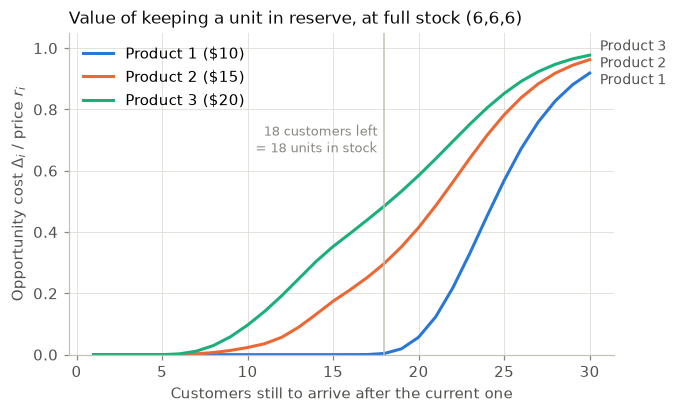

In [9]:
remaining = np.arange(1, HORIZON + 1)          # customers still to come after the current one
frac = np.array([rm.opportunity_costs(V_dp[HORIZON - m])[(slice(None),) + CAPACITY] / PRICES for m in remaining])
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for i in range(rm.N_PROD):
    ax.plot(remaining, frac[:, i], color=SLOT[i], label=f"Product {i + 1} (${PRICES[i]:.0f})")
    ax.text(30.6, [0.895, 0.95, 1.005][i], f"Product {i + 1}", va="center", color=INK2, fontsize=9)
ax.axvline(18, color=AXIS, linewidth=1)
ax.text(17.6, 0.66, "18 customers left\n= 18 units in stock", ha="right", color=MUTED, fontsize=8.5)
ax.set_xlabel("Customers still to arrive after the current one")
ax.set_ylabel(r"Opportunity cost $\Delta_i$ / price $r_i$")
ax.set_ylim(0, 1.05)
ax.set_title("Value of keeping a unit in reserve, at full stock (6,6,6)", loc="left")
ax.legend(loc="upper left")
fig.savefig(FIG / "fig2_opportunity_cost.png")
plt.show()

**Why the DP does this.**
* **Product 3 is kept in reserve for type A.** Type A almost only buys product 3, so the DP shows A everything (71% of A decisions use {1,2,3}).
  It mostly hides product 3 from B and C, who are happy with products 1 and 2: B is mostly shown {1,2} (49%), and C is shown {1} or {1,2} (35% each).
* **Opportunity costs reverse the price ranking.** At full stock with many customers to come, every unit is likely to sell eventually, so each unit's
  opportunity cost $\Delta_i$ is close to its price (Figure 2). What remains, the adjusted price $\rho_i = r_i-\Delta_i$, is largest for product 1:
  $\rho = (1.20, 0.84, 0.71)$. Product 1 is the unit the DP is least sure of selling later, because type A rarely buys it. By Proposition 2 the
  optimal sets are then nested in the order 1, 2, 3, which gives {1}, {1,2}, {1,2,3}. That is exactly the DP's opening move: A → {1,2,3}, B → {1,2}, C → {1,2}.
* **Behaviour reverses near the end.** When fewer customers remain than units in stock (left of the vertical line in Figure 2), product 1's
  opportunity cost falls to 0. Not every unit can be sold, so the DP shifts toward the expensive products and behaves more like greedy.

## 7. When does planning ahead matter? (load sweep)

**Question:** how does the value of the DP over simpler rules depend on how scarce inventory is? We keep $c=(6,6,6)$
and vary the number of customers $T$; the simulation itself is $T=30$. All values are exact.

policy,DP (optimal) (% of $270),Show all in stock (% of $270),Inventory balancing (% of $270),Myopic greedy (% of $270)
T,,,,
3,14.9,14.1,14.8,14.9
6,29.8,28.3,29.6,29.8
9,44.5,42.4,43.7,44.5
12,58.5,56.1,56.9,58.4
15,70.8,68.8,68.6,70.2
18,80.9,79.8,78.2,78.5
21,89.3,88.5,86.1,84.5
24,95.2,94.4,92.3,89.5
27,98.3,97.7,96.3,93.7


Shortfall vs DP ($):


policy,Show all in stock,Inventory balancing,Myopic greedy
T,,,
3,1.98,0.10,0.00
6,3.97,0.55,0.00
9,5.73,2.21,0.02
12,6.43,4.12,0.24
15,5.30,5.93,1.66
18,2.88,7.26,6.36
21,2.03,8.42,12.74
24,1.97,7.77,15.16
27,1.58,5.30,12.35


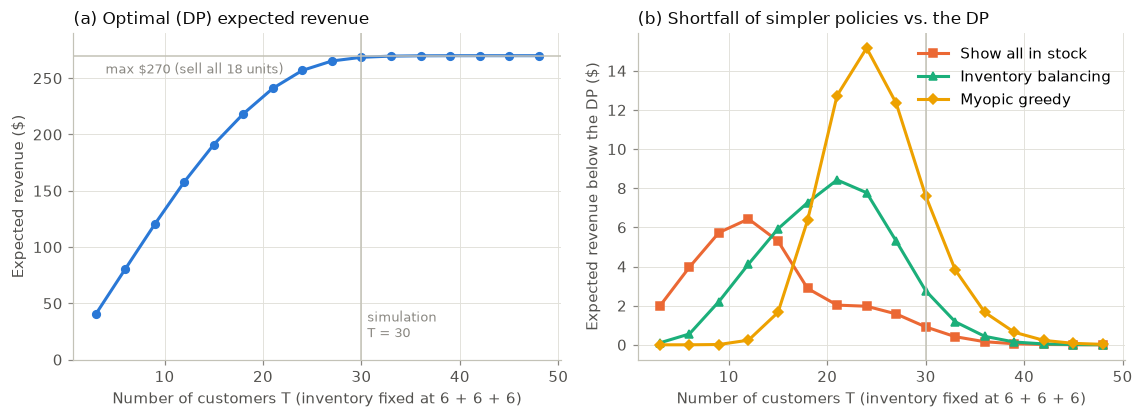

DP - greedy gap is largest at T = 24 ($15.16); at T = 30 it is $7.61


In [10]:
T_grid = np.arange(3, 49, 3)
sweep = []
for T in T_grid:
    V_T, pol_T = rm.solve_dp(P_mnl, p_hat, T=T)
    cand = {"DP (optimal)": pol_T,
            "Show all in stock": rm.policy_show_all(T=T),
            "Inventory balancing": rm.policy_inventory_balancing(P_mnl, T=T),
            "Myopic greedy": rm.policy_greedy(P_mnl, T=T)}
    for name, pol in cand.items():
        sweep.append({"T": T, "policy": name,
                      "revenue": rm.start_value(rm.evaluate_policy(pol, P_emp, p_hat, T=T))})
sweep = pd.DataFrame(sweep).pivot(index="T", columns="policy", values="revenue")[list(POLICY_STYLE)]
display((sweep / (PRICES @ CAPACITY) * 100).round(1).rename(columns=lambda c: c + " (% of $270)"))

shortfall = sweep.rsub(sweep["DP (optimal)"], axis=0).drop(columns="DP (optimal)")
print("Shortfall vs DP ($):")
display(shortfall.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
col, mk = POLICY_STYLE["DP (optimal)"]
ax1.plot(sweep.index, sweep["DP (optimal)"], color=col, marker=mk, markersize=5)
ax1.axhline(PRICES @ CAPACITY, color=AXIS, linewidth=1)
ax1.text(4, PRICES @ CAPACITY - 6, "max $270 (sell all 18 units)", ha="left", va="top", color=MUTED, fontsize=8.5)
ax1.set_ylim(0, 290)
ax1.set_ylabel("Expected revenue ($)")
ax1.set_title("(a) Optimal (DP) expected revenue", loc="left")
for name in shortfall.columns:
    col, mk = POLICY_STYLE[name]
    ax2.plot(shortfall.index, shortfall[name], color=col, marker=mk, markersize=5, label=name)
ax2.set_ylabel("Expected revenue below the DP ($)")
ax2.set_title("(b) Shortfall of simpler policies vs. the DP", loc="left")
ax2.legend(loc="upper right")
for ax in (ax1, ax2):
    ax.axvline(30, color=AXIS, linewidth=1)
    ax.set_xlabel("Number of customers T (inventory fixed at 6 + 6 + 6)")
ax1.text(30.6, 20, "simulation\nT = 30", color=MUTED, fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / "fig3_load_sweep.png")
plt.show()
gap = sweep["DP (optimal)"] - sweep["Myopic greedy"]
print(f"DP - greedy gap is largest at T = {gap.idxmax()} (${gap.max():.2f}); at T = 30 it is ${gap.loc[30]:.2f}")

**When does planning ahead matter?** Each simple rule fails in a different regime (Figure 3b):
* **Few customers (T ≤ 12):** inventory rarely runs out, greedy is essentially optimal (within \$0.24), and show-all is the worst rule
  (up to \$6.43 behind). Offering cheap products then only cannibalizes sales of expensive ones.
* **Demand slightly above supply (T ≈ 18 to 30):** greedy's shortfall peaks at \$15.16 when T = 24, and inventory balancing's at \$8.42 when T = 21.
  Here the cheap units must be sold deliberately.
* **Very many customers (T ≥ 39):** almost everything sells under any rule.

The simulation (T = 30) sits on the downslope of the greedy curve. The DP's lead is \$7.61 over greedy, \$2.76 over inventory balancing, and \$0.91 over show-all.
The DP is the only policy that is near the top across the whole range.

## 8. Robustness to the unknown arrival process

**Question:** the arrival process of types is unknown. How much does each policy lose relative to an *oracle* that
knows the true process? The DP and adaptive DP are always planned with the data's mix $\hat p=(11,7,12)/30$; only
the oracle knows the truth. Scenarios:
* **i.i.d. mixes:** the base mix, uniform, A-/B-/C-heavy (0.6 on one type), A-only, and no type C. The oracle is the DP solved with the true mix. Values are exact.
* **Block orders:** exactly 11 A, 7 B, 12 C arriving in blocks (e.g. "CBA" means all C's, then all B's, then all A's). The oracle is the DP that knows the order. Values are exact.
* **Fixed composition, random order:** exactly 11/7/12 shuffled uniformly. Values are from 20,000 simulated runs; this scenario has no exact oracle in our code.

**Adaptive DP** starts from the prior Dirichlet($m\hat p$) and, at each arrival, re-solves the DP with the posterior-mean mix
(certainty-equivalent re-solving). We test prior strengths $m = 5$ (learns fast) and $m = 30$ (learns slowly).

In [11]:
truth = P_emp
markov = {"DP (optimal)": pol_dp,
          "Show all in stock": policies["Show all in stock"],
          "Inventory balancing": policies["Inventory balancing"],
          "Myopic greedy": policies["Myopic greedy"]}
adaptive = {f"Adaptive DP (m={m})": rm.AdaptiveDP(P_mnl, p_hat, m) for m in (5, 30)}
rng = np.random.default_rng(SEED + 1)

rows = []
mixes = {"base mix (11/7/12)": p_hat, "uniform": [1/3, 1/3, 1/3], "A-heavy": [.6, .2, .2], "B-heavy": [.2, .6, .2],
         "C-heavy": [.2, .2, .6], "A only": [1, 0, 0], "no C": [.6, .4, 0]}
for name, q in mixes.items():
    q = np.asarray(q, float)
    _, pol_or = rm.solve_dp(truth, q)
    row = {"scenario": f"iid: {name}", "oracle": rm.start_value(rm.evaluate_policy(pol_or, truth, q))}
    row.update({n: rm.start_value(rm.evaluate_policy(p, truth, q)) for n, p in markov.items()})
    tys = rm.draw_arrivals(rng, 20_000, ("iid", q))
    U = rng.random(tys.shape)
    for n, a in adaptive.items():
        sim_a, _ = rm.simulate(a, truth, tys, U)
        sim_d, _ = rm.simulate(pol_dp, truth, tys, U)
        # paired correction: exact DP value + simulated (adaptive - DP) difference on common random numbers
        row[n] = row["DP (optimal)"] + (sim_a - sim_d).mean()
    rows.append(row)

comp = [11, 7, 12]
for perm in itertools.permutations(range(K)):
    order = np.concatenate([[k] * comp[k] for k in perm])
    onehot = np.eye(K)[order]
    _, pol_or = rm.solve_dp(truth, onehot)
    row = {"scenario": "order: " + "".join(TYPES[k] for k in perm),
           "oracle": rm.start_value(rm.evaluate_policy(pol_or, truth, onehot))}
    row.update({n: rm.start_value(rm.evaluate_policy(p, truth, onehot)) for n, p in markov.items()})
    row.update({n: rm.start_value(rm.evaluate_policy(a.table_for_order(order), truth, onehot)) for n, a in adaptive.items()})
    rows.append(row)

tys = rm.draw_arrivals(rng, 20_000, ("fixed_counts", comp))
U = rng.random(tys.shape)
row = {"scenario": "11/7/12 random order", "oracle": np.nan}
row.update({n: rm.simulate(p, truth, tys, U)[0].mean() for n, p in {**markov, **adaptive}.items()})
rows.append(row)

robust = pd.DataFrame(rows).set_index("scenario")
pol_cols = list(markov) + list(adaptive)
regret = robust[pol_cols].rsub(robust["oracle"], axis=0)
display(robust.round(2))
print("Regret = oracle - policy ($):")
display(regret.round(2))
print("Worst-case regret over scenarios with an oracle:")
display(regret.max().round(2).to_frame("worst regret ($)"))

,oracle,DP (optimal),Show all in stock,Inventory balancing,Myopic greedy,Adaptive DP (m=5),Adaptive DP (m=30)
scenario,,,,,,,
iid: base mix (11/7/12),268.59,268.57,267.66,265.81,260.97,268.49,268.58
iid: uniform,268.67,268.64,267.89,266.19,261.55,268.60,268.63
iid: A-heavy,260.63,260.44,257.78,254.49,247.84,260.33,260.48
iid: B-heavy,268.88,268.67,268.55,267.30,262.28,268.82,268.74
iid: C-heavy,269.68,269.61,269.55,268.81,266.41,269.68,269.64
iid: A only,201.10,201.10,201.10,199.71,197.13,201.17,201.14
iid: no C,257.14,256.86,255.63,252.60,247.08,256.88,256.95
order: ABC,269.45,269.18,269.44,268.79,268.30,268.23,269.02
order: ACB,269.27,268.53,268.89,267.36,261.40,266.61,268.24


Regret = oracle - policy ($):


,DP (optimal),Show all in stock,Inventory balancing,Myopic greedy,Adaptive DP (m=5),Adaptive DP (m=30)
scenario,,,,,,
iid: base mix (11/7/12),0.01,0.93,2.78,7.62,0.10,0.01
iid: uniform,0.03,0.78,2.48,7.12,0.07,0.04
iid: A-heavy,0.19,2.86,6.14,12.80,0.31,0.15
iid: B-heavy,0.22,0.34,1.58,6.61,0.07,0.14
iid: C-heavy,0.08,0.14,0.87,3.27,0.01,0.04
iid: A only,0.00,0.00,1.39,3.98,-0.07,-0.04
iid: no C,0.29,1.52,4.54,10.06,0.27,0.20
order: ABC,0.27,0.01,0.66,1.15,1.22,0.44
order: ACB,0.74,0.38,1.91,7.87,2.66,1.04


Worst-case regret over scenarios with an oracle:


,worst regret ($)
DP (optimal),2.79
Show all in stock,3.14
Inventory balancing,12.17
Myopic greedy,23.85
Adaptive DP (m=5),14.00
Adaptive DP (m=30),5.18


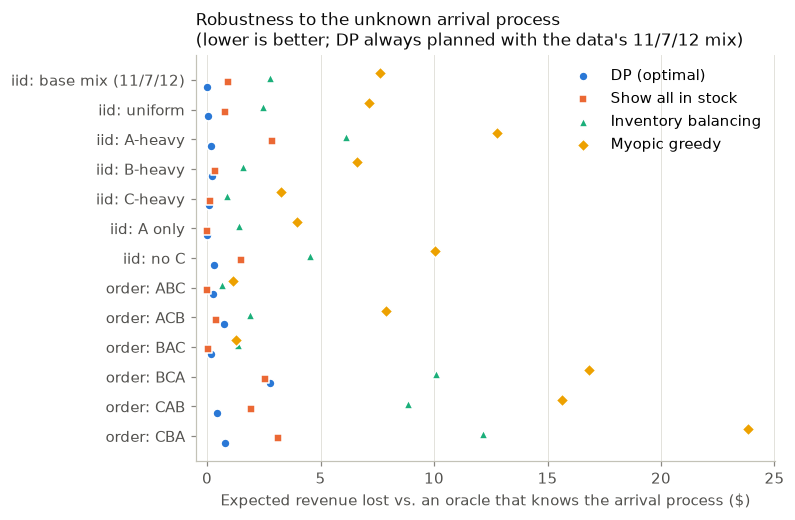

In [12]:
reg = regret.dropna()
fig, ax = plt.subplots(figsize=(6.8, 4.8))
ypos = np.arange(len(reg))[::-1]
for j, (name, (col, mk)) in enumerate(POLICY_STYLE.items()):
    ax.scatter(reg[name], ypos + (j - 1.5) * 0.15, color=col, marker=mk, s=34, edgecolor="white",
               linewidth=1, label=name, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels(reg.index)
ax.set_xlabel("Expected revenue lost vs. an oracle that knows the arrival process ($)")
ax.set_title("Robustness to the unknown arrival process\n(lower is better; DP always planned with the data's 11/7/12 mix)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(left=-0.5)
ax.legend(loc="upper right")
fig.savefig(FIG / "fig4_robustness.png")
plt.show()

**Takeaways.**
* **Shifted i.i.d. mixes barely matter.** The DP planned with the data's mix stays within \$0.29 of the oracle in all 7 mixes. Its decisions are driven
  mainly by *who buys what* (the choice model), and much less by how often each type shows up.
* **The hardest cases are the two orders in which all type A customers arrive last (BCA, CBA), for every policy.** Type A rarely buys products
  1 and 2, so all 12 of those units must go to the first 19 customers, and a policy planned for mixed arrivals does not push them hard enough.
  The DP's worst regret is \$2.79. Show-all is a close, robust runner-up (worst \$3.14, and slightly better than the DP in 4 of the 6 orders).
  Greedy and inventory balancing lose much more (up to \$23.85 and \$12.17) when C customers come first: greedy shows them {2,3}, so they use up product 3.
* **Learning the mix online does not pay.** Adaptive DP improves on the DP by at most \$0.15 in the i.i.d. scenarios. After a streak of one type,
  it over-weights that type for the rest of the game, and loses up to \$14.00 (m = 5) or \$5.18 (m = 30) under block orders.
  (Small negative regrets for adaptive DP are simulation noise.)
* With exactly 11 A, 7 B and 12 C in random order, the DP has the highest revenue of all policies tested (\$269.00).

## 9. Robustness to estimation error, and MNL vs. raw frequencies

**Question:** the choice probabilities are estimated from finite data. How much revenue could estimation error cost,
and should we plan with the per-type MNL or with the raw observed frequencies?

Parametric bootstrap: we resample each (type, assortment) cell of the data from the observed frequencies, keeping the
designed cell sizes. For each resample $b$ we re-estimate the model, re-solve the DP, and evaluate the resulting policy
exactly under a fixed "truth". We report the loss relative to the DP that knows the truth.

In [13]:
B = 200
rng = np.random.default_rng(SEED + 2)
truths = {"empirical": P_emp, "MNL": P_mnl}
best = {name: rm.start_value(rm.evaluate_policy(rm.solve_dp(P, p_hat)[1], P, p_hat)) for name, P in truths.items()}
records = []
for b in range(B):
    cb = np.zeros_like(counts)
    for k in range(K):
        for s in range(1, rm.N_SUB):
            cb[k, s] = rng.multinomial(counts[k, s].sum(), P_emp[k, s])
    models_b = {"MNL": rm.mnl_model(np.array([rm.fit_mnl(cb[k])["v"] for k in range(K)])),
                "empirical": rm.empirical_model(cb)}
    pb = cb.sum((1, 2)) / cb.sum()
    for plan_name, Pb in models_b.items():
        _, pol_b = rm.solve_dp(Pb, pb)
        for truth_name, Pt in truths.items():
            records.append({"plan with": plan_name, "truth": truth_name,
                            "loss": best[truth_name] - rm.start_value(rm.evaluate_policy(pol_b, Pt, p_hat)),
                            "same first decisions": all(pol_b[0][CAPACITY + (k,)] == pol_dp[0][CAPACITY + (k,)] for k in range(K))})
boot = pd.DataFrame(records)
display(boot.groupby(["truth", "plan with"]).agg(mean_loss=("loss", "mean"), p95_loss=("loss", lambda s: s.quantile(.95)),
                                                  max_loss=("loss", "max"),
                                                  share_same_first_decisions=("same first decisions", "mean")).round(3))

mean_loss  p95_loss  max_loss  share_same_first_decisions
truth     plan with                                                           
MNL       MNL            0.000     0.001     0.002                        1.00
          empirical      0.039     0.110     0.144                        0.67
empirical MNL            0.014     0.016     0.019                        1.00
          empirical      0.015     0.036     0.059                        0.67

**Takeaways.**
* **Estimation error is negligible for decisions.** Re-estimating the MNL on resampled data leaves the DP's opening moves unchanged in all 200
  resamples, and costs on average \$0.014 (at most \$0.019) when the truth is the empirical model. This also bounds the cost of the mild MNL
  misfit for type B: well under a cent per customer.
* **The MNL beats raw frequencies as a planning model.** Planning with raw frequencies changes the opening moves in a third of the resamples,
  because noise breaks near-ties between assortments. Its mean loss is similar under the empirical truth (\$0.015) and larger under the MNL truth (\$0.039).
  The MNL smooths noise using the structure that Section 3 found in the data.

## 10. Recommended policy and how to use it in the simulation

**Recommendation:** the exact DP built on the per-type MNL fit with the data's type mix (`pol_dp`). The cell below exports it as a
lookup table: for customer number $t$, current inventory, and the arriving type, the table gives the assortment to show.

During the live simulation, the easier route is `python play.py`. It asks for each arriving customer's type,
prints the assortment to show, then asks what they bought and updates the inventory. It supports undo (`u`) and
resuming mid-game (`--customer 12 --inventory 3 4 2`).

In [14]:
table = rm.policy_table_frame(pol_dp, V_dp)
table.to_csv("policy_table.csv", index=False)
print(f"Saved policy_table.csv ({len(table):,} rows). Example rows:")
display(table.query("customer_number == 1 and inv_product1 == 6 and inv_product2 == 6 and inv_product3 == 6"))
display(table.query("customer_number == 20 and inv_product1 == 2 and inv_product2 == 1 and inv_product3 == 3"))

Saved policy_table.csv (30,870 rows). Example rows:


,customer_number,inv_product1,inv_product2,inv_product3,customer_type,show,expected_revenue_from_here
1026,1,6,6,6,A,"{1,2,3}",268.676
1027,1,6,6,6,B,"{1,2}",268.676
1028,1,6,6,6,C,"{1,2}",268.676


,customer_number,inv_product1,inv_product2,inv_product3,customer_type,show,expected_revenue_from_here
19875,20,2,1,3,A,"{1,2,3}",93.072
19876,20,2,1,3,B,"{1,2,3}",93.072
19877,20,2,1,3,C,"{1,3}",93.072


## 11. Assumptions and limitations

* **Behaviour in the simulation matches the training data.** The data look like a designed experiment from the same generator, but if the
  simulation's customers behave differently (different weights, learning, strategic waiting), the policy must be re-estimated.
  The code takes any `P[k, S, j]` table.
* **Arrival process.** The DP is provably optimal only for i.i.d. types with a known mix. Section 8 tests shifted mixes and adversarial orders
  and finds small regret, but this is not a worst-case guarantee over all possible sequences.
* **MNL for type B** shows a mild misfit. Section 9 shows that it costs less than \$0.02 in expectation.
* **Structural results** (Proposition 2) rely on the MNL. The DP itself does not: the DP on the empirical model is solved by enumeration.
* **One game is one draw.** Even the optimal policy has a revenue standard deviation of about \$5.5 over a 30-customer game, so a single
  realized outcome says little about which policy is better. The comparisons above are exact expectations or large paired simulations for this reason.
* Prices and inventory are fixed inputs, as in the simulation (pricing decisions are out of scope).